# Valoración de ISA (Interconexión Eléctrica S.A. E.S.P.) — DCF en Python

Réplica en Python del modelo en Excel del proyecto final de **Renta Variable 2026 (EIA/TBS)**.
Sigue las mismas 9 etapas de Damodaran y da el mismo resultado que el Excel: **$23.763 por acción** (DCF del FCFF al 30-oct-2026).

**Cómo leerlo:** cada sección corresponde a una hoja del Excel. Todos los insumos vienen de los CSV de `data/`.
Para probar otro escenario, cambie el CSV o el diccionario `S` y vuelva a correr todo.

Unidades: COP miles de millones (COP bn), salvo los valores por acción (COP).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.options.display.float_format = '{:,.4f}'.format
DATA = Path('data') if Path('data').exists() else Path('../data')

sup = pd.read_csv(DATA / 'isa_supuestos.csv')
S = dict(zip(sup.clave, sup.valor.astype(float)))          # supuestos escalares
anual = pd.read_csv(DATA / 'isa_proyeccion_anual.csv', index_col='año')
conv = pd.read_csv(DATA / 'isa_conversion_2026.csv', index_col='moneda').fillna(0)
mensual = pd.read_csv(DATA / 'isa_mercado_mensual.csv', parse_dates=['fecha'])

YEARS = list(range(2025, 2037))          # 2025A + 2026E-2036E
sup[['grupo', 'clave', 'valor', 'unidad', 'descripcion']].head(12)

,grupo,clave,valor,unidad,descripcion
0,supuestos,precio,"27,220.0000",COP,Precio de la acción
1,supuestos,default_usa,0.0023,%,Diferencial de default de EE. UU.
2,supuestos,erp,0.0417,%,Prima de riesgo de mercado maduro (ERP implícita)
3,supuestos,crp_col,0.0285,%,CRP Colombia
4,supuestos,def_col,0.0187,%,Diferencial de default soberano Colombia
5,supuestos,crp_bra,0.0324,%,CRP Brasil
6,supuestos,def_bra,0.0213,%,Diferencial de default soberano Brasil
7,supuestos,crp_per,0.0207,%,CRP Perú
8,supuestos,def_per,0.0136,%,Diferencial de default soberano Perú
9,supuestos,crp_chi,0.0110,%,CRP Chile


## Etapa 2 — Riesgo y retorno histórico (ISA vs. MSCI COLCAP, 60 meses)

In [2]:
m = mensual.set_index('fecha')
r = pd.DataFrame({
    'isa_tr': m.isa_total_return.pct_change(), 'colcap_tr': m.colcap_total_return.pct_change(),
    'isa': m.isa_precio.pct_change(), 'colcap': m.colcap_precio.pct_change(),
}).dropna()
rf_m = (m.tasa_banrep_pct.shift(1) / 100 / 12).loc[r.index]

def max_drawdown(idx):
    return (idx / idx.cummax() - 1).min()

riesgo = pd.DataFrame({
    'Retorno aritmético anual': r[['isa_tr', 'colcap_tr']].mean() * 12,
    'Volatilidad anual': r[['isa_tr', 'colcap_tr']].std() * np.sqrt(12),
    'Sharpe anual': (r[['isa_tr', 'colcap_tr']].sub(rf_m, axis=0)).mean() * 12 / (r[['isa_tr', 'colcap_tr']].std() * np.sqrt(12)),
    'Máximo drawdown': [max_drawdown(m.isa_total_return), max_drawdown(m.colcap_total_return)],
}).T
riesgo.columns = ['ISA', 'MSCI COLCAP']
riesgo

,ISA,MSCI COLCAP
Retorno aritmético anual,0.1424,0.2229
Volatilidad anual,0.2918,0.1992
Sharpe anual,0.1364,0.6042
Máximo drawdown,-0.3529,-0.2803


## Etapa 3 — Moneda, tasa libre de riesgo y riesgo país

Valoramos en **COP nominal**. La tasa libre de riesgo es el Treasury menos el default de EE. UU., y se pasa a COP con Fisher.
La prima de riesgo país (CRP) se pondera por los ingresos de cada país (lambda = 1).

In [3]:
paises = ['col', 'bra', 'per', 'chi', 'pan']
pesos = np.array([S[f'peso_{p}'] for p in paises])
rf_usd = S['treasury_10a'] - S['default_usa']
rf_cop = (1 + rf_usd) * (1 + S['pi_cop_lp']) / (1 + S['pi_usd_lp']) - 1
crp = pesos @ np.array([S[f'crp_{p}'] for p in paises])
default_sob = pesos @ np.array([S[f'def_{p}'] for p in paises])
pd.Series({'Rf USD': rf_usd, 'Rf COP (Fisher)': rf_cop, 'CRP ponderada': crp, 'Default soberano ponderado': default_sob})

Rf USD                       0.0470
Rf COP (Fisher)              0.0710
CRP ponderada                0.0264
Default soberano ponderado   0.0174
dtype: float64

## Etapa 4 — Beta

Primero la regresión propia contra el COLCAP (como contraste). La beta que usamos es la **bottom-up de Damodaran**,
ponderada por negocio y re-apalancada con Hamada. La regresión contra el COLCAP mide el riesgo frente a un índice local,
y ISA pesa ~7% en ese índice.

In [4]:
beta_reg, alfa = np.polyfit(r.colcap, r.isa, 1)
r2 = np.corrcoef(r.colcap, r.isa)[0, 1] ** 2

# Beta bottom-up: pesos por ingresos sin construcción 2025
ing25 = np.array([S['ing_energia_2025'], S['ing_vias_2025'], S['ing_telecom_2025']])
w_neg = ing25 / ing25.sum()
beta_u = w_neg @ np.array([S['bu_energia'], S['bu_vias'], S['bu_telecom']])
pd.Series({'Beta regresión (precio, mensual)': beta_reg, 'R²': r2, 'Observaciones': len(r),
           'Beta desapalancada ponderada': beta_u})

Beta regresión (precio, mensual)    1.0980
R²                                  0.5529
Observaciones                      59.0000
Beta desapalancada ponderada        0.4773
dtype: float64

## Etapa 6 (insumo) — Proyección 2026E-2036E

Hoja `Proyeccion` del Excel. Los ingresos sin construcción se proyectan por segmento y país:

`ingreso_t = ingreso_{t-1} × (1 + inflación del indexador) × (1 + variación cambiaria) × (1 − erosión desde 2031) + rendimiento × capex_{t-1} + eventos`

Primero va el **efecto de conversión de 2026**: el balance de 2025 está a tasas de dic-25 y los flujos a la tasa spot de la fecha de corte.

In [5]:
A = anual.copy().astype(float)
pi_cop, pi_usd = S['pi_cop_lp'], S['pi_usd_lp']

# Macro: desde 2029 inflación de largo plazo; desde 2028 paridad para las monedas
for y in YEARS:
    if y >= 2029:
        A.loc[y, 'inflacion_usa'] = pi_usd
        A.loc[y, 'ipc_colombia'] = pi_cop
    if y >= 2028:
        A.loc[y, 'cop_usd'] = A.loc[y - 1, 'cop_usd'] * (1 + pi_cop) / (1 + pi_usd)
        A.loc[y, 'cop_brl'] = A.loc[y - 1, 'cop_brl'] * (1 + pi_cop) / (1 + A.loc[y, 'ipca_brasil'])
        A.loc[y, 'cop_clp'] = A.loc[y - 1, 'cop_clp'] * (1 + pi_cop) / (1 + A.loc[y, 'inflacion_chile_uf'])
for mon in ['usd', 'brl', 'clp']:
    A[f'var_{mon}'] = A[f'cop_{mon}'].pct_change()

# Conversión 2026: variación de cada moneda entre el cierre de dic-25 y el spot del 30-oct-2026
spot = {'USD': S['usdcop_spot'], 'BRL': S['usdcop_spot'] / S['usdbrl_spot'], 'CLP': S['usdcop_spot'] / S['usdclp_spot']}
var_fx = pd.Series({k: spot[k] / conv.loc[k, 'cierre_dic25'] - 1 for k in spot} | {'COP': 0.0})
var_pond = {c: (var_fx * conv[c]).sum() for c in ['peso_capital_invertido', 'peso_deuda_neta', 'peso_minoritario', 'peso_cocontroladas']}

deuda_neta_2025 = S['deuda_financiera_2025'] - S['caja_2025'] - S['otros_act_fin_2025']
capital_inv_2025 = S['deuda_financiera_2025'] + S['patrimonio_total_2025'] - S['caja_2025'] - S['otros_act_fin_2025'] - S['inv_cocontroladas_2025']
conv_capital = capital_inv_2025 * var_pond['peso_capital_invertido']
conv_deuda = deuda_neta_2025 * var_pond['peso_deuda_neta']
conv_minor = S['interes_minoritario_2025'] * var_pond['peso_minoritario']
conv_cocon = S['inv_cocontroladas_2025'] * var_pond['peso_cocontroladas']
conv_ori = conv_capital + conv_cocon - conv_deuda - conv_minor   # otro resultado integral

# IE Madeira (se consolida desde ago-2026)
deuda_madeira = S['deuda_neta_madeira_brl'] * spot['BRL'] / 1000
libros_salen = (S['libros_madeira'] + S['libros_garanhuns']) * (1 + var_pond['peso_cocontroladas'])
pd.Series({'Var. USD': var_fx['USD'], 'Var. BRL': var_fx['BRL'], 'Var. CLP': var_fx['CLP'],
           'Efecto en capital invertido': conv_capital, 'Efecto en deuda neta': conv_deuda,
           'Efecto en minoritario': conv_minor, 'Efecto en co-controladas': conv_cocon, 'Efecto en patrimonio (ORI)': conv_ori})

Var. USD                          -0.1496
Var. BRL                          -0.1398
Var. CLP                          -0.2152
Efecto en capital invertido   -6,020.4318
Efecto en deuda neta          -3,424.4428
Efecto en minoritario         -1,482.2690
Efecto en co-controladas        -608.0105
Efecto en patrimonio (ORI)    -1,721.7305
dtype: float64

### Capex e ingresos por segmento

2026E-2030E: plan de inversión de ISA. 2031E-2036E: el capex / ingresos de cada segmento converge linealmente al valor de 2036E (Supuestos).

In [6]:
# segmento: (columna de ingresos, columna de capex, indexador, moneda, negocio)
SEG = {
    'energia_brasil':   ('ipca_brasil', 'brl', 'energia'),
    'energia_colombia': ('inflacion_usa', 'usd', 'energia'),
    'energia_peru':     ('inflacion_usa', 'usd', 'energia'),
    'energia_chile':    ('inflacion_usa', 'usd', 'energia'),
    'vias_chile':       ('inflacion_chile_uf', 'clp', 'vias'),
    'vias_colombia':    ('ipc_colombia', None, 'vias'),
    'vias_panama':      ('inflacion_usa', 'usd', 'vias'),
    'telecom':          ('ipc_colombia', None, 'telecom'),
}
ING = pd.DataFrame(index=YEARS, dtype=float)
CAPEX = pd.DataFrame(index=YEARS, dtype=float)
for s in SEG:
    ING.loc[2025, s] = A.loc[2025, f'ing_{s}']
    CAPEX[s] = A[f'capex_{s}']

# Eventos puntuales en Brasil (COP bn): reversión del ajuste de la RBSE (2026), fin del componente financiero, IE Madeira
ev_brasil = pd.Series(0.0, index=YEARS)
ev_brasil[2026] += S['rbse_ajuste_2025_brl'] * (1 + A.loc[2026, 'ipca_brasil']) * A.loc[2026, 'cop_brl'] / 1000
ev_brasil += (A.fin_rbse_brl.fillna(0) + A.madeira_incremental_brl.fillna(0)) * A.cop_brl / 1000
ev_vias_chile = A.evento_vias_chile.fillna(0)

for y in YEARS[1:]:
    for s, (idx, mon, neg) in SEG.items():
        crec = (1 + A.loc[y, idx]) * (1 + (A.loc[y, f'var_{mon}'] if mon else 0))
        erosion = (1 - S[f'erosion_{neg}']) if y >= 2031 else 1
        evento = ev_brasil[y] if s == 'energia_brasil' else ev_vias_chile[y] if s == 'vias_chile' else 0
        ING.loc[y, s] = ING.loc[y - 1, s] * crec * erosion + S[f'rend_capex_{neg}'] * CAPEX.loc[y - 1, s] + evento
        if y >= 2031:   # capex / ingresos converge al valor de 2036E
            ratio30 = CAPEX.loc[2030, s] / ING.loc[2030, s]
            CAPEX.loc[y, s] = (ratio30 + (S[f'capex_ing_2036_{neg}'] - ratio30) * (y - 2030) / 6) * ING.loc[y, s]

ingresos = ING.sum(axis=1)
capex = CAPEX.sum(axis=1)
pd.DataFrame({'Ingresos sin construcción': ingresos, 'Crecimiento': ingresos.pct_change(),
              'Capex': capex, 'Capex / ingresos': capex / ingresos}).T

,2025,2026,2027,2028,2029,2030,2031,2032,2033,2034,2035,2036
Ingresos sin construcción,"11,186.0000","11,887.8686","12,432.9287","13,458.4502","14,642.4703","15,840.4264","16,559.2687","17,303.4226","18,073.1290","18,868.6463","19,690.2621","20,538.3071"
Crecimiento,NaN,0.0627,0.0459,0.0825,0.0880,0.0818,0.0454,0.0449,0.0445,0.0440,0.0435,0.0431
Capex,"6,277.0000","6,800.0000","6,600.0000","5,800.0000","4,800.0000","4,099.9000","4,203.3332","4,303.5160","4,400.5500","4,494.6532","4,586.1710","4,675.5861"
Capex / ingresos,0.5611,0.5720,0.5308,0.4310,0.3278,0.2588,0.2538,0.2487,0.2435,0.2382,0.2329,0.2277


### EBITDA, NOPAT, reinversión, FCFF y ROIC; luego la utilidad por acción y la deuda neta

In [7]:
kd_cop = (1 + rf_usd + default_sob + S['spread_empresa']) * (1 + pi_cop) / (1 + pi_usd) - 1   # Kd marginal (Etapa 5)
t_ef = np.mean([-S[f'impuesto_{y}'] / (S[f'uai_{y}'] - S[f'cocontroladas_{y}']) for y in range(2022, 2026)])
acc = S['acciones']

P = pd.DataFrame(index=YEARS, dtype=float)
P['ingresos'] = ingresos
P['capex'] = capex
P['margen'] = A.margen_ebitda_op
P['ebitda'] = P.ingresos * P.margen
P.loc[2025, 'ebitda'] = S['ebitda_2025'] - S['cocontroladas_2025'] - S['utilidad_construccion_2025']
P['da'] = P.ingresos * S['da_ingresos']
P.loc[2025, 'da'] = -S['da_2025']
P['ebit'] = P.ebitda - P.da
P['tasa_imp'] = t_ef
P['nopat'] = P.ebit * (1 - P.tasa_imp)

kd_path = pd.Series({y: A.loc[2026, 'costo_fin_deuda_neta'] + (kd_cop - A.loc[2026, 'costo_fin_deuda_neta']) * (y - 2026) / 10 for y in YEARS[1:]})
cobro_rbse = A.cobro_rbse_brl.fillna(0) * A.cop_brl / 1000
salida_mp = {2026: (S['mp_madeira_2025'] + S['mp_garanhuns_2025']) * (1 + S['g_cocontroladas']) * 5 / 12,
             2027: (S['mp_madeira_2025'] + S['mp_garanhuns_2025']) * (1 + S['g_cocontroladas']) ** 2 * 7 / 12}

P.loc[2025, ['cocontroladas', 'deuda_neta', 'minoritario', 'utilidad', 'dpa', 'minoritario_libros', 'patrimonio_libros']] = [
    S['cocontroladas_2025'], deuda_neta_2025, -S['minoritario_resultado_2025'], S['utilidad_neta_2025'], S['dpa_2025'],
    S['interes_minoritario_2025'], S['patrimonio_total_2025'] - S['interes_minoritario_2025']]

for y in YEARS[1:]:
    p = y - 1
    P.loc[y, 'adquisiciones'] = S['adquisicion_2026'] if y == 2026 else 0
    P.loc[y, 'conc_no_cobradas'] = A.loc[y, 'concesiones_no_cobradas_pct'] * P.loc[y, 'ingresos'] - cobro_rbse[y]
    P.loc[y, 'capital_trabajo'] = S['ct_incremental'] * (P.loc[y, 'ingresos'] - P.loc[p, 'ingresos'])
    P.loc[y, 'reinversion'] = P.loc[y, ['capex', 'adquisiciones', 'conc_no_cobradas', 'capital_trabajo']].sum() - P.loc[y, 'da']
    P.loc[y, 'fcff'] = P.loc[y, 'nopat'] - P.loc[y, 'reinversion']
    if y == 2026:
        P.loc[y, 'capital_inicial'] = capital_inv_2025 + conv_capital
    elif y == 2027:
        P.loc[y, 'capital_inicial'] = P.loc[p, 'capital_inicial'] + P.loc[p, 'reinversion'] + libros_salen + deuda_madeira
    else:
        P.loc[y, 'capital_inicial'] = P.loc[p, 'capital_inicial'] + P.loc[p, 'reinversion']
    # De la utilidad operativa a la utilidad por acción
    P.loc[y, 'cocontroladas'] = P.loc[p, 'cocontroladas'] * (1 + S['g_cocontroladas']) - salida_mp.get(y, 0)
    P.loc[y, 'gasto_fin'] = kd_path[y] * P.loc[p, 'deuda_neta']
    P.loc[y, 'uai'] = P.loc[y, 'ebit'] + P.loc[y, 'cocontroladas'] - P.loc[y, 'gasto_fin']
    P.loc[y, 'impuesto'] = (P.loc[y, 'uai'] - P.loc[y, 'cocontroladas']) * P.loc[y, 'tasa_imp']
    P.loc[y, 'minoritario'] = (P.loc[y, 'uai'] - P.loc[y, 'impuesto']) * S['part_minoritarios_utilidad']
    P.loc[y, 'utilidad'] = P.loc[y, 'uai'] - P.loc[y, 'impuesto'] - P.loc[y, 'minoritario']
    P.loc[y, 'dpa'] = P.loc[y, 'utilidad'] / acc * 1000 * S['payout']
    P.loc[y, 'div_isa'] = P.loc[p, 'dpa'] * acc / 1000
    P.loc[y, 'div_minoritarios'] = P.loc[p, 'minoritario'] * S['payout_minoritarios']
    P.loc[y, 'deuda_neta'] = (P.loc[p, 'deuda_neta'] - P.loc[y, 'fcff'] + P.loc[y, 'gasto_fin'] * (1 - P.loc[y, 'tasa_imp'])
                              + P.loc[y, 'div_isa'] + P.loc[y, 'div_minoritarios'] - P.loc[y, 'cocontroladas']
                              + ((-S['aporte_minoritarios_2026'] + conv_deuda + deuda_madeira) if y == 2026 else 0))
    P.loc[y, 'minoritario_libros'] = (P.loc[p, 'minoritario_libros'] + P.loc[y, 'minoritario'] - P.loc[y, 'div_minoritarios']
                                      + ((S['aporte_minoritarios_2026'] + conv_minor) if y == 2026 else 0))
    P.loc[y, 'patrimonio_libros'] = P.loc[p, 'patrimonio_libros'] + P.loc[y, 'utilidad'] - P.loc[y, 'div_isa'] + (conv_ori if y == 2026 else 0)

P['upa'] = P.utilidad / acc * 1000
P['roic'] = P.nopat / P.capital_inicial
P['tasa_reinversion'] = P.reinversion / P.nopat
P['roe'] = P.utilidad / P.patrimonio_libros.rolling(2).mean()
P['deuda_neta_ebitda'] = P.deuda_neta / (P.ebitda + P.cocontroladas)
P['cobertura'] = (P.ebit + P.cocontroladas) / P.gasto_fin

cols = ['ingresos', 'ebitda', 'ebit', 'nopat', 'capex', 'reinversion', 'fcff', 'capital_inicial', 'roic',
        'tasa_reinversion', 'utilidad', 'upa', 'dpa', 'deuda_neta', 'roe', 'deuda_neta_ebitda']
P[cols].T.style.format('{:,.3f}')

,2025,2026,2027,2028,2029,2030,2031,2032,2033,2034,2035,2036
ingresos,"11,186.000","11,887.869","12,432.929","13,458.450","14,642.470","15,840.426","16,559.269","17,303.423","18,073.129","18,868.646","19,690.262","20,538.307"
ebitda,"7,577.000","8,202.629","8,740.349","9,609.333","10,454.724","11,310.064","11,823.318","12,354.644","12,904.214","13,472.213","14,058.847","14,664.351"
ebit,"6,499.000","7,132.721","7,621.385","8,398.073","9,136.901","9,884.426","10,332.984","10,797.336","11,277.632","11,774.035","12,286.724","12,815.904"
nopat,"4,943.717","5,425.782","5,797.503","6,388.321","6,950.339","7,518.973","7,860.186","8,213.413","8,578.769","8,956.377","9,346.374","9,748.915"
capex,"6,277.000","6,800.000","6,600.000","5,800.000","4,800.000","4,099.900","4,203.333","4,303.516","4,400.550","4,494.653","4,586.171","4,675.586"
reinversion,nan,"6,442.950","5,468.407","4,907.425","4,108.774","3,328.175","3,349.215","3,389.035","3,422.422","3,449.482","3,470.449","3,485.690"
fcff,nan,"-1,017.168",329.096,"1,480.896","2,841.565","4,190.797","4,510.971","4,824.378","5,156.348","5,506.896","5,875.925","6,263.225"
capital_inicial,nan,"46,815.568","55,298.223","60,766.630","65,674.054","69,782.829","73,111.004","76,460.219","79,849.254","83,271.676","86,721.158","90,191.607"
roic,nan,0.116,0.105,0.105,0.106,0.108,0.108,0.107,0.107,0.108,0.108,0.108
tasa_reinversion,nan,1.187,0.943,0.768,0.591,0.443,0.426,0.413,0.399,0.385,0.371,0.358


## Etapa 5 — Costo de capital (CAPM con riesgo país y WACC en COP)

La deuda para el WACC es la deuda financiera 2026E (deuda neta proyectada + caja). El patrimonio a mercado
incluye a los minoritarios (ISA Energia Brasil a mercado y el resto a libros), porque la deuda es consolidada.

In [8]:
cap_bursatil = S['precio'] * acc / 1000
caja_2026 = S['caja_2026']
deuda_2026 = P.loc[2026, 'deuda_neta'] + caja_2026
minor_isaeb = S['cap_isaeb'] * (1 - S['part_isa_en_isaeb'])
minor_resto = P.loc[2026, 'minoritario_libros'] - (1 - S['part_isa_en_isaeb']) * S['patrimonio_isaeb_brl'] * spot['BRL'] / 1000
minoritario_mkt = minor_isaeb + minor_resto
patrimonio_mkt = cap_bursatil + minoritario_mkt

d_e = deuda_2026 / patrimonio_mkt
beta = beta_u * (1 + (1 - S['t_marginal']) * d_e)                       # Hamada
ke_usd = rf_usd + beta * S['erp'] + S['lambda'] * crp
ke = (1 + ke_usd) * (1 + pi_cop) / (1 + pi_usd) - 1                     # Fisher
kd_at = kd_cop * (1 - S['t_marginal'])
wd = deuda_2026 / (deuda_2026 + patrimonio_mkt)
wacc = (1 - wd) * ke + wd * kd_at

pd.Series({'Beta re-apalancada (Hamada)': beta, 'D/E a mercado': d_e, 'Ke USD': ke_usd, 'Ke COP': ke,
           'Kd COP antes de impuestos': kd_cop, 'Kd después de impuestos': kd_at, 'D/(D+E)': wd, 'WACC COP': wacc,
           'WACC real': (1 + wacc) / (1 + pi_cop) - 1})

Beta re-apalancada (Hamada)   0.7560
D/E a mercado                 0.8715
Ke USD                        0.1049
Ke COP                        0.1303
Kd COP antes de impuestos     0.1031
Kd después de impuestos       0.0691
D/(D+E)                       0.4657
WACC COP                      0.1018
WACC real                     0.0523
dtype: float64

## Etapa 7 — Crecimiento y valor intrínseco (DCF del FCFF)

- Se valora al **31-dic-2026**: se descuentan los FCFF 2027E-2036E al WACC.
- **Valor terminal** desde 2037 con g = 4,7% (crecimiento real 0%) y reinversión = g / RONIC, con RONIC = ROIC de 2036E.
- Puente: + co-controladas + caja − deuda − interés minoritario.
- Fecha: se suma la cuota de dividendo del 16-dic ($872) y se trae el valor 62 días al Ke hasta el 30-oct-2026.

In [9]:
g = S['g']
proj = P.loc[2027:2036]
t = np.arange(1, 11)
fd = 1 / (1 + wacc) ** t
pv_fcff = (proj.fcff * fd).sum()

ronic = P.loc[2036, 'roic']
nopat_2037 = P.loc[2036, 'nopat'] * (1 + g)
fcff_2037 = nopat_2037 * (1 - g / ronic)
vt = fcff_2037 / (wacc - g)
pv_vt = vt * fd[-1]
valor_operativo = pv_fcff + pv_vt

cocon_2026 = S['inv_cocontroladas_2025'] + conv_cocon - libros_salen   # co-controladas en libros 2026E
equity = valor_operativo + cocon_2026 + caja_2026 - deuda_2026 - minoritario_mkt
valor_31dic = equity / acc * 1000
cuota_dic = S['cuota_dic_pct'] * S['dpa_2025']
factor_fecha = 1 / (1 + ke) ** (S['dias_a_31dic'] / 365)
valor_dcf = (valor_31dic + cuota_dic) * factor_fecha

puente = pd.Series({
    'VP de los FCFF 2027E-2036E': pv_fcff, 'VP del valor terminal': pv_vt, 'Valor operativo de la firma': valor_operativo,
    '(+) Co-controladas (libros 2026E)': cocon_2026, '(+) Caja 2026E': caja_2026, '(−) Deuda financiera 2026E': -deuda_2026,
    '(−) Interés minoritario': -minoritario_mkt, 'Patrimonio de ISA': equity,
    'Valor por acción al 31-dic-2026': valor_31dic, '(+) Cuota de dividendo 16-dic': cuota_dic,
    '× Factor de fecha (62 días al Ke)': factor_fecha, 'VALOR POR ACCIÓN DCF (30-oct-2026)': valor_dcf})
print(f'% del valor que viene del valor terminal: {pv_vt / valor_operativo:.1%}')
print(f'Diferencia vs precio de mercado (${S["precio"]:,.0f}): {valor_dcf / S["precio"] - 1:.1%}')
puente.to_frame('COP').style.format('{:,.2f}')

% del valor que viene del valor terminal: 64.5%
Diferencia vs precio de mercado ($27,220): -12.7%


,COP
VP de los FCFF 2027E-2036E,"21,944.15"
VP del valor terminal,"39,927.73"
Valor operativo de la firma,"61,871.87"
(+) Co-controladas (libros 2026E),"1,928.87"
(+) Caja 2026E,"4,065.00"
(−) Deuda financiera 2026E,"-33,578.51"
(−) Interés minoritario,"-8,377.59"
Patrimonio de ISA,"25,909.66"
Valor por acción al 31-dic-2026,"23,390.97"
(+) Cuota de dividendo 16-dic,872.00


In [10]:
assert abs(valor_dcf - 23763.32) < 0.5, valor_dcf     # mismo valor que el Excel
print(f'OK: el DCF en Python da ${valor_dcf:,.2f} por acción, igual al Excel ($23.763).')

OK: el DCF en Python da $23,763.32 por acción, igual al Excel ($23.763).


### Crecimiento fundamental y chequeos del valor terminal

In [11]:
pd.Series({
    'g fundamental NOPAT (reinversión × ROIC, 2027E-2030E)': P.loc[2027:2030, 'tasa_reinversion'].mean() * P.loc[2027:2030, 'roic'].mean(),
    'ROIC 2036E (= RONIC)': ronic, 'WACC': wacc, 'Reinversión de madurez g/RONIC': g / ronic,
    'VT / (EBIT + D&A) 2036E': vt / (P.loc[2036, 'ebit'] + P.loc[2036, 'da']),
    'ROIC incremental 2030E-2036E': (P.loc[2036, 'nopat'] - P.loc[2030, 'nopat']) / P.loc[2030:2035, 'reinversion'].sum(),
    'EV/EBITDA 2027E implícito': (valor_operativo + cocon_2026) / (P.loc[2027, 'ebitda'] + P.loc[2027, 'cocontroladas']),
    'P/U 2027E implícito': valor_31dic / P.loc[2027, 'upa'],
})

g fundamental NOPAT (reinversión × ROIC, 2027E-2030E)    0.0727
ROIC 2036E (= RONIC)                                     0.1081
WACC                                                     0.1018
Reinversión de madurez g/RONIC                           0.4348
VT / (EBIT + D&A) 2036E                                  7.1786
ROIC incremental 2030E-2036E                             0.1093
EV/EBITDA 2027E implícito                                7.0619
P/U 2027E implícito                                     10.6694
dtype: float64

### Verificación de Fisher: el mismo DCF en USD

Los flujos se pasan a USD con la tasa de cambio esperada por paridad de inflación, y se descuentan al WACC en USD.
El valor convertido al spot debe ser idéntico.

In [12]:
fx = S['usdcop_spot'] * ((1 + pi_cop) / (1 + pi_usd)) ** t
wacc_usd = (1 + wacc) * (1 + pi_usd) / (1 + pi_cop) - 1
g_usd = (1 + g) * (1 + pi_usd) / (1 + pi_cop) - 1
fcff_usd = proj.fcff.values / fx * 1000
vt_usd = fcff_2037 / (fx[-1] * (1 + pi_cop) / (1 + pi_usd)) * 1000 / (wacc_usd - g_usd)
vo_usd = (fcff_usd / (1 + wacc_usd) ** t).sum() + vt_usd / (1 + wacc_usd) ** 10
print(f'Valor operativo en USD: {vo_usd:,.1f} mn → en COP al spot: {vo_usd * S["usdcop_spot"] / 1000:,.2f} bn '
      f'(diferencia con COP: {vo_usd * S["usdcop_spot"] / 1000 - valor_operativo:.2e})')

Valor operativo en USD: 19,365.7 mn → en COP al spot: 61,871.87 bn (diferencia con COP: 5.82e-11)


### Conciliación FCFF – FCFE

FCFE = FCFF − intereses × (1 − t) + Δ deuda neta, descontado al Ke. La diferencia con el FCFF (~1%) se explica
porque la deuda neta proyectada cambia la estructura de capital año a año, mientras el WACC supone un D/(D+E) constante.

In [13]:
dn = P.deuda_neta
fcfe = proj.fcff - dn.shift(1).loc[2027:2036] * kd_cop * (1 - S['t_marginal']) + dn.diff().loc[2027:2036]
equity_fcfe = (fcfe / (1 + ke) ** t).sum() + (vt - dn[2036]) / (1 + ke) ** 10
equity_fcff = valor_operativo - dn[2026]
valor_fcfe = ((equity_fcfe + cocon_2026 - minoritario_mkt) / acc * 1000 + cuota_dic) * factor_fecha
pd.Series({'Patrimonio consolidado por FCFE': equity_fcfe, 'Patrimonio consolidado por FCFF': equity_fcff,
           'Diferencia %': equity_fcfe / equity_fcff - 1, 'Valor por acción FCFE (30-oct)': valor_fcfe})

Patrimonio consolidado por FCFE   32,015.0726
Patrimonio consolidado por FCFF   32,358.3678
Diferencia %                          -0.0106
Valor por acción FCFE (30-oct)    23,459.7825
dtype: float64

### DDM multietapa (al Ke)

In [14]:
dpa_pagado = P.dpa.shift(1).loc[2027:2036]
roe_estable = P.loc[2036, 'roe']
payout_estable = 1 - g / roe_estable
precio_terminal = P.loc[2036, 'upa'] * payout_estable / (ke - g)
valor_ddm_31dic = (dpa_pagado / (1 + ke) ** t).sum() + precio_terminal / (1 + ke) ** 10
valor_ddm = (valor_ddm_31dic + cuota_dic) * factor_fecha
pd.Series({'ROE estable 2036E': roe_estable, 'Payout estable': payout_estable, 'Precio terminal 2036E': precio_terminal,
           'Valor DDM (30-oct)': valor_ddm})

ROE estable 2036E            0.1283
Payout estable               0.6338
Precio terminal 2036E   30,032.2141
Valor DDM (30-oct)      16,646.9290
dtype: float64

### Sensibilidad: WACC × g (valor por acción al 31-dic-2026)

In [15]:
def valor_accion(w, gg):
    tv = P.loc[2036, 'nopat'] * (1 + gg) * (1 - gg / ronic) / (w - gg)
    vo = (proj.fcff / (1 + w) ** t).sum() + tv / (1 + w) ** 10
    return (vo + cocon_2026 + caja_2026 - deuda_2026 - minoritario_mkt) / acc * 1000

waccs = wacc + np.arange(-0.015, 0.0151, 0.005)
gs = g + np.arange(-0.01, 0.0101, 0.005)
sens = pd.DataFrame([[valor_accion(w, gg) for gg in gs] for w in waccs],
                    index=[f'WACC {w:.2%}' for w in waccs], columns=[f'g {gg:.1%}' for gg in gs])
sens.style.format('{:,.0f}').background_gradient(cmap='RdYlGn', axis=None)

,g 3.7%,g 4.2%,g 4.7%,g 5.2%,g 5.7%
WACC 8.68%,"41,534","43,548","46,023","49,159","53,287"
WACC 9.18%,"34,005","35,277","36,794","38,651","40,992"
WACC 9.68%,"27,752","28,524","29,419","30,478","31,762"
WACC 10.18%,"22,479","22,910","23,391","23,938","24,572"
WACC 10.68%,"17,976","18,170","18,372","18,584","18,808"
WACC 11.18%,"14,086","14,116","14,128","14,119","14,083"
WACC 11.68%,"10,695","10,610","10,494","10,339","10,135"


### Qué tiene que creer el mercado para pagar $27.220

In [16]:
precio_31dic = S['precio'] * (1 + ke) ** (S['dias_a_31dic'] / 365) - cuota_dic

def biseccion(f, a, b, n=200):
    for _ in range(n):
        c = (a + b) / 2
        a, b = (c, b) if f(a) * f(c) > 0 else (a, c)
    return (a + b) / 2

wacc_impl = biseccion(lambda w: valor_accion(w, g) - precio_31dic, 0.06, 0.15)
g_impl = biseccion(lambda gg: valor_accion(wacc, gg) - precio_31dic, 0.0, wacc - 0.001)
pd.Series({'Precio expresado al 31-dic-2026': precio_31dic, 'WACC implícito (g base)': wacc_impl,
           'g implícito (WACC base)': g_impl, 'g real implícito': (1 + g_impl) / (1 + pi_cop) - 1})

Precio expresado al 31-dic-2026   26,920.3225
WACC implícito (g base)                0.0988
g implícito (WACC base)                0.0700
g real implícito                       0.0219
dtype: float64

## Etapa 9 — Decisión

Valor justo = 70% DCF + 30% comparables (el valor por comparables viene de la hoja E8 del Excel).
Precio objetivo a 12 meses = valor justo × (1 + Ke) − dividendo esperado.

In [17]:
div_esperado = cuota_dic + 0.2 * P.loc[2026, 'dpa']
valor_justo = S['peso_dcf'] * valor_dcf + S['peso_comparables'] * S['valor_comparables']
po = round(valor_justo * (1 + ke) - div_esperado, -2)
retorno = po / S['precio'] - 1 + div_esperado / S['precio']
decision = pd.Series({'Valor DCF': valor_dcf, 'Valor comparables': S['valor_comparables'], 'Valor justo': valor_justo,
                      'Precio objetivo 12m': po, 'Precio de mercado': S['precio'], 'Retorno total esperado': retorno,
                      'Ke (retorno exigido)': ke})
print('Recomendación: VENDER' if retorno < ke else 'Recomendación: no VENDER')
decision

Recomendación: VENDER


Valor DCF                23,763.3236
Valor comparables        26,708.9141
Valor justo              24,647.0007
Precio objetivo 12m      26,800.0000
Precio de mercado        27,220.0000
Retorno total esperado        0.0243
Ke (retorno exigido)          0.1303
dtype: float64

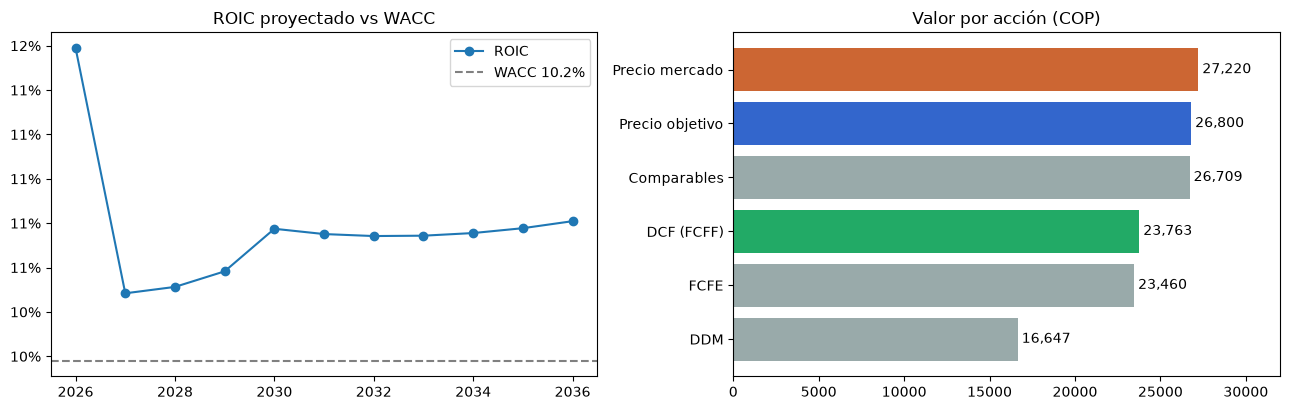

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
P.loc[2026:2036, ['roic']].plot(ax=ax[0], marker='o', label='ROIC')
ax[0].axhline(wacc, color='gray', ls='--', label=f'WACC {wacc:.1%}')
ax[0].set_title('ROIC proyectado vs WACC'); ax[0].legend(['ROIC', f'WACC {wacc:.1%}'])
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
vals = {'DDM': valor_ddm, 'FCFE': valor_fcfe, 'DCF (FCFF)': valor_dcf, 'Comparables': S['valor_comparables'],
        'Precio objetivo': po, 'Precio mercado': S['precio']}
ax[1].barh(list(vals), list(vals.values()), color=['#9aa', '#9aa', '#2a6', '#9aa', '#36c', '#c63'])
for i, v in enumerate(vals.values()):
    ax[1].text(v, i, f' {v:,.0f}', va='center')
ax[1].set_title('Valor por acción (COP)'); ax[1].set_xlim(0, 32000)
plt.tight_layout(); plt.show()